# Hito 3 — Evaluación del modelo desplegado
### Predictor de resultados de la English Premier League (Victoria local / Empate / Victoria visitante)

**Institución:** Escuela Colombiana de Ingeniería Julio Garavito · **Curso:** PTIA · **Grupo:** 04
**Integrantes:** Juan Diego Gaitán, José Alejandro Martínez, Oscar David Lasso, Carlos Andrés Sánchez

Este notebook **no entrena nada**: lee los artefactos producidos por `python -m src.train` (carpeta `models/`) y el servicio `prediction_service.py`, y presenta la evidencia de la validación del Hito 3:

1. Datos y partición cronológica.
2. Selección de arquitectura en validación.
3. Comparación con modelos de referencia en el conjunto de prueba.
4. Regla de decisión: *argmax* frente a umbrales bayesianos.
5. Calibración de las probabilidades.
6. Prueba prospectiva en la temporada 2025/26.
7. Casos de prueba con partidos reales (entradas, salida esperada y salida lograda).

El notebook del Hito 2 (`Proyecto_Red_Neuronal_Profunda_EPL.ipynb`) se conserva como registro del modelo anterior.

**Ejecutar:** `pip install -r requirements-notebook.txt` (Python 3.10–3.13) y luego *Run All*.

In [1]:
import json
import os
import sys
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / "prediction_service.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

with open(ROOT / "models" / "training_summary.json", encoding="utf-8") as f:
    summary = json.load(f)
with open(ROOT / "models" / "calibration.json", encoding="utf-8") as f:
    calibration = json.load(f)

pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid")

DEPLOYED = next(
    r["model"] for r in summary["test_results"]
    if r["model"].startswith(summary["selected_architecture"]) and "Calibrado" in r["model"]
)
print("Versión del modelo:   ", summary["model_version"])
print("Arquitectura elegida: ", summary["selected_architecture"], f"({summary['total_params']:,} parámetros)")
print("Fila del benchmark:   ", DEPLOYED)
print("Entrenado (UTC):      ", summary["trained_at_utc"], "| semilla", summary["seed"])
print("Entorno:              ", summary["environment"])

Versión del modelo:    3.0.0-hito3-backend
Arquitectura elegida:  Residual_Deep_MLP_3L (6,189 parámetros)
Fila del benchmark:    Residual_Deep_MLP_3L (Calibrado T=1.172)
Entrenado (UTC):       2026-11-22T20:26:22.093946+00:00 | semilla 42
Entorno:               {'tensorflow': '2.21.0', 'keras': '3.15.1', 'scikit_learn': '1.9.0', 'numpy': '2.3.5', 'pandas': '2.3.3'}


## 1. Datos y partición cronológica

Las tres fuentes se consolidan en un único historial de la EPL sin huecos. La partición es estrictamente temporal: el modelo nunca ve partidos posteriores a los de entrenamiento, y el preprocesador (imputación de Elo, mercado estimado desde Elo y `StandardScaler`) se ajusta **solo** con el conjunto de entrenamiento.

In [2]:
s = summary["dataset_splits"]
def rango(seasons):
    return f"{seasons[0]} – {seasons[-1]}"

splits = pd.DataFrame(
    [
        ["Entrenamiento", rango(s["train_seasons"]), s["train_matches"]],
        ["Validación", rango(s["val_seasons"]), s["val_matches"]],
        ["Prueba", rango(s["test_seasons"]), s["test_matches"]],
        ["Prospectivo (fuera de muestra)", rango(s["prospective_seasons"]), s["prospective_matches"]],
    ],
    columns=["Conjunto", "Temporadas", "Partidos"],
)
print(f"Partidos cargados: {s['total_matches_loaded']:,} · Variables de entrada: {s['n_features']}")
print("Distribución de clases en entrenamiento (L / E / V):", s["train_priors"])
splits

Partidos cargados: 9,900 · Variables de entrada: 45
Distribución de clases en entrenamiento (L / E / V): [0.464861, 0.255728, 0.279412]


,Conjunto,Temporadas,Partidos
0,Entrenamiento,2000/01 – 2016/17,6460
1,Validación,2017/18 – 2020/21,1520
2,Prueba,2021/22 – 2024/25,1520
3,Prospectivo (fuera de muestra),2025/26 – 2025/26,380


## 2. Selección de arquitectura en validación

Se entrenaron cuatro redes candidatas y se eligió la de menor *log loss* en **validación** (2017/18–2020/21). El conjunto de prueba no participa en esta decisión.

In [3]:
cand = pd.DataFrame(summary["candidate_models_val_selection"]).rename(
    columns={"name": "Arquitectura", "total_params": "Parámetros", "best_epoch": "Mejor época",
             "epochs_trained": "Épocas", "val_loss": "Log loss validación", "learning_rate": "Tasa aprendizaje"}
)
cand.sort_values("Log loss validación")

,Arquitectura,Parámetros,Mejor época,Épocas,Log loss validación,Tasa aprendizaje
2,Residual_Deep_MLP_3L,6189,25,43,0.9579,0.0008
0,Deep_MLP_Hito2,17571,7,25,0.9614,0.0010
3,Residual_Deep_MLP_4L,17901,29,47,0.9641,0.0008
1,Compact_Deep_MLP,5987,48,66,0.9674,0.0010


## 3. Comparación con modelos de referencia (prueba 2021/22–2024/25)

Todos los modelos se evalúan sobre los mismos partidos nunca vistos. *Log loss* y *Brier* miden la calidad de las probabilidades (más bajo es mejor); la exactitud y la F1 del empate miden la clase elegida con *argmax*.

In [4]:
COLS = {"model": "Modelo", "accuracy": "Exactitud", "macro_f1": "F1 macro", "f1_D": "F1 empate",
        "draws_predicted": "Empates marcados", "log_loss": "Log loss", "brier_score": "Brier",
        "brier_skill_score": "BSS", "top_label_ece": "ECE"}

def tabla(rows):
    df = pd.DataFrame(rows)[list(COLS)].rename(columns=COLS)
    return df.set_index("Modelo")

test = tabla(summary["test_results"])
test.style.format({"Exactitud": "{:.2%}", "F1 macro": "{:.2%}", "F1 empate": "{:.2%}", "Empates marcados": "{:.0f}",
                   "Log loss": "{:.4f}", "Brier": "{:.4f}", "BSS": "{:+.4f}", "ECE": "{:.4f}"}) \
    .highlight_max(subset=["Exactitud", "F1 macro", "F1 empate", "BSS"], color="#c8e6c9") \
    .highlight_min(subset=["Log loss", "Brier"], color="#c8e6c9")

,Exactitud,F1 macro,F1 empate,Empates marcados,Log loss,Brier,BSS,ECE
Modelo,,,,,,,,
Dummy (Prior/Mayoría),44.54%,20.54%,0.00%,0,1.0687,0.6465,+0.0000,0.0195
Bet365 (Cuotas Implícitas),56.91%,42.18%,0.00%,0,0.9458,0.5598,+0.1340,0.0306
Regresión Logística (C=0.01),56.91%,42.80%,2.23%,9,0.9495,0.5621,+0.1304,0.0328
HistGradientBoosting (Tuned Val),56.51%,42.21%,1.11%,10,0.9541,0.5645,+0.1268,0.0240
Deep MLP Hito 2 (128-64-32-16),55.72%,41.62%,0.56%,7,0.9569,0.5674,+0.1223,0.0248
Residual_Deep_MLP_3L (Sin Calibrar),56.71%,45.47%,10.92%,53,0.9525,0.5633,+0.1287,0.0282
Residual_Deep_MLP_3L (Calibrado T=1.172),56.71%,45.47%,10.92%,53,0.9516,0.5631,+0.1289,0.0312
Ablación Sin Cuotas (40 vars),54.74%,41.78%,3.74%,24,0.9726,0.5770,+0.1074,0.0275


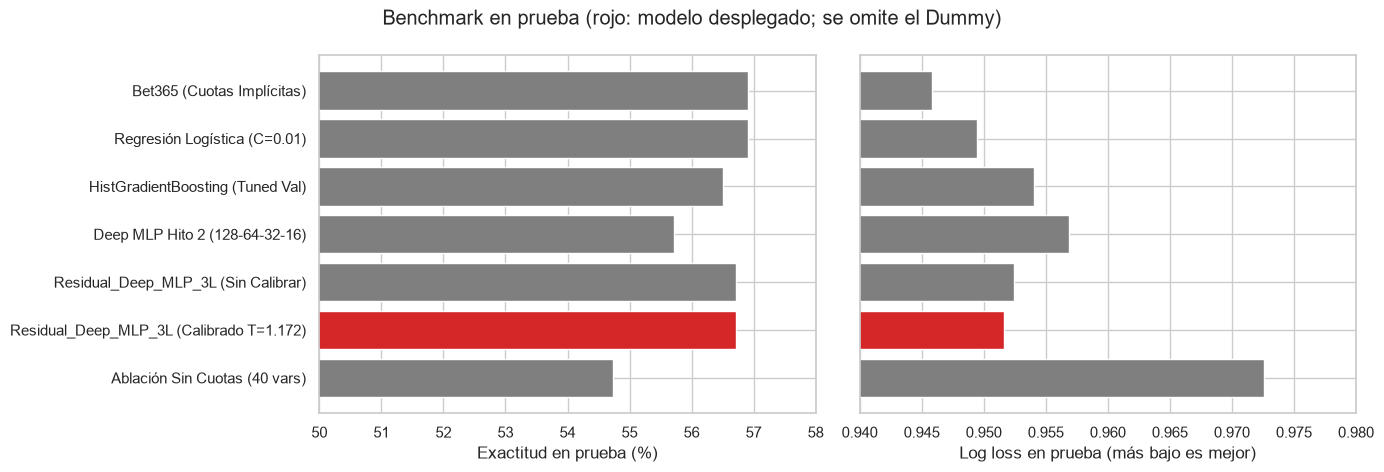

Modelo desplegado: exactitud 56.71%, log loss 0.9516
Mejor exactitud del benchmark: 56.91% (Bet365 (Cuotas Implícitas), Regresión Logística (C=0.01))
Diferencia: 0.20 puntos porcentuales


In [5]:
plot_df = test.drop(index=[m for m in test.index if m.startswith("Dummy")]).reset_index()
colors = ["#d62728" if m == DEPLOYED else "#7f7f7f" for m in plot_df["Modelo"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].barh(plot_df["Modelo"], plot_df["Exactitud"] * 100, color=colors)
axes[0].set_xlim(50, 58)
axes[0].set_xlabel("Exactitud en prueba (%)")
axes[1].barh(plot_df["Modelo"], plot_df["Log loss"], color=colors)
axes[1].set_xlim(0.94, 0.98)
axes[1].set_xlabel("Log loss en prueba (más bajo es mejor)")
axes[1].set_yticklabels([])
for ax in axes:
    ax.invert_yaxis()
fig.suptitle("Benchmark en prueba (rojo: modelo desplegado; se omite el Dummy)")
plt.tight_layout()
plt.show()

mine = test.loc[DEPLOYED]
best_acc = test["Exactitud"].max()
print(f"Modelo desplegado: exactitud {mine['Exactitud']:.2%}, log loss {mine['Log loss']:.4f}")
print(f"Mejor exactitud del benchmark: {best_acc:.2%} ({', '.join(test.index[test['Exactitud'] == best_acc])})")
print(f"Diferencia: {(best_acc - mine['Exactitud']) * 100:.2f} puntos porcentuales")

## 4. Regla de decisión: *argmax* frente a umbrales bayesianos

Con *argmax* el modelo casi nunca elige el empate, porque rara vez es la clase con mayor probabilidad. Los umbrales bayesianos multiplican las probabilidades por pesos ajustados en validación (empate × 1,49, visitante × 1,08) para equilibrar las clases. Las probabilidades no cambian: solo cambia la clase que se destaca, por eso *log loss* y *Brier* son idénticos en ambas reglas.

,argmax,"bayesiana [1.0, 1.49, 1.08]"
Exactitud,56.71%,52.11%
Exactitud balanceada,49.08%,48.26%
F1 macro,45.47%,48.39%
F1 empate,10.92%,27.53%
Empates marcados,53,362


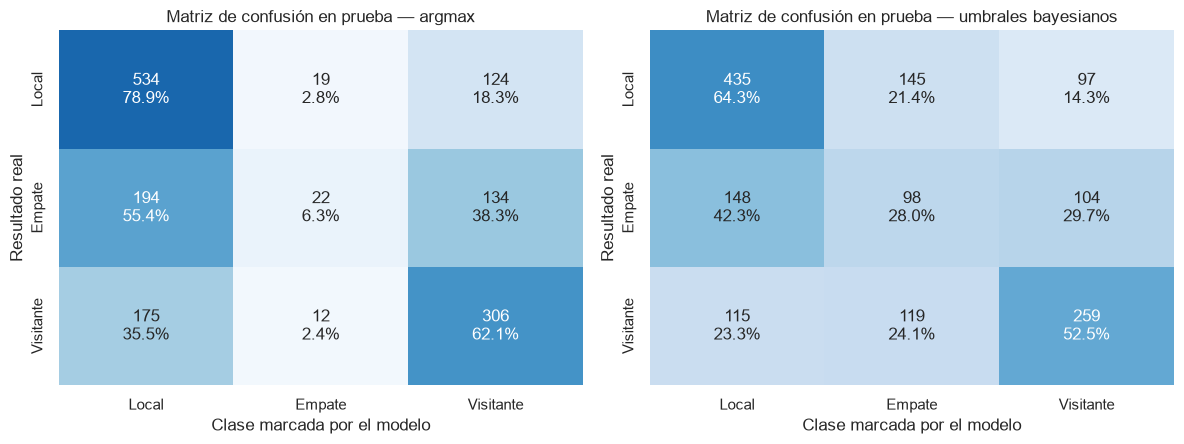

In [6]:
row = next(r for r in summary["test_results"] if r["model"] == DEPLOYED)
bay = row["bayesian_threshold_metrics"]
reglas = pd.DataFrame(
    {
        "argmax": [row["accuracy"], row["balanced_accuracy"], row["macro_f1"], row["f1_D"], row["draws_predicted"]],
        f"bayesiana {bay['weights']}": [bay["accuracy"], bay["balanced_accuracy"], bay["macro_f1"], bay["f1_D"], bay["draws_predicted"]],
    },
    index=["Exactitud", "Exactitud balanceada", "F1 macro", "F1 empate", "Empates marcados"],
)
display(reglas.style.format("{:.2%}", subset=pd.IndexSlice[["Exactitud", "Exactitud balanceada", "F1 macro", "F1 empate"], :])
        .format("{:.0f}", subset=pd.IndexSlice[["Empates marcados"], :]))

labels = ["Local", "Empate", "Visitante"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, cm, title in [(axes[0], row["confusion_matrix"], "argmax"), (axes[1], bay["confusion_matrix"], "umbrales bayesianos")]:
    cm = np.array(cm)
    norm = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cm[i, j]}\n{norm[i, j]:.1%}" for j in range(3)] for i in range(3)])
    sns.heatmap(norm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_xlabel("Clase marcada por el modelo")
    ax.set_ylabel("Resultado real")
    ax.set_title(f"Matriz de confusión en prueba — {title}")
plt.tight_layout()
plt.show()

## 5. Calibración de las probabilidades

El *temperature scaling* divide los *logits* entre una temperatura $T$ ajustada en validación. Si las probabilidades están bien calibradas, cuando el modelo dice "60 %" el favorito debería ganar cerca del 60 % de las veces: los puntos del diagrama deben quedar cerca de la diagonal.

Temperatura T = 1.1723 (ajustada en validación)


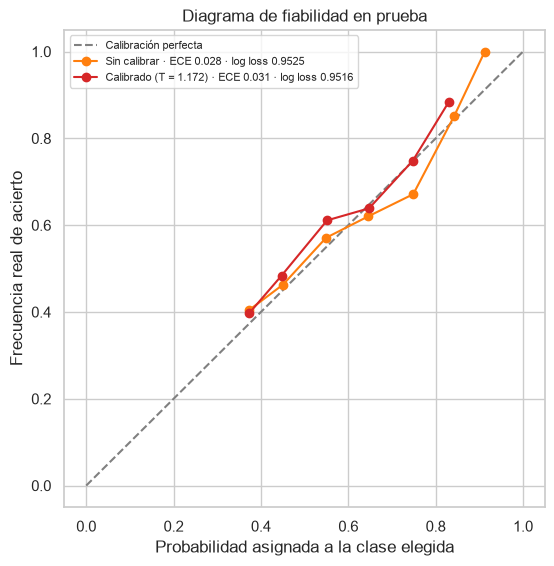

,Probabilidad media predicha,Frecuencia real
Local,43.03%,44.54%
Empate,24.73%,23.03%
Visitante,32.23%,32.43%


In [7]:
uncal = next(r for r in summary["test_results"] if r["model"].startswith(summary["selected_architecture"]) and "Sin Calibrar" in r["model"])
print(f"Temperatura T = {calibration['temperature']:.4f} (ajustada en validación)")

fig, ax = plt.subplots(figsize=(6.2, 6.2))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
for r, color, name in [(uncal, "#ff7f0e", "Sin calibrar"), (row, "#d62728", f"Calibrado (T = {calibration['temperature']:.3f})")]:
    bins = [b for b in r["calibration_bins"]["top_label_bins"] if b["count"]]
    ax.plot([b["mean_confidence"] for b in bins], [b["empirical_accuracy"] for b in bins], "o-", color=color,
            label=f"{name} · ECE {r['top_label_ece']:.3f} · log loss {r['log_loss']:.4f}")
ax.set_xlabel("Probabilidad asignada a la clase elegida")
ax.set_ylabel("Frecuencia real de acierto")
ax.set_title("Diagrama de fiabilidad en prueba")
ax.legend(loc="upper left", fontsize=8)
plt.show()

freq = pd.DataFrame({"Probabilidad media predicha": row["mean_predicted_probs"], "Frecuencia real": row["empirical_freqs"]},
                    index=labels)
freq.style.format("{:.2%}")

## 6. Prueba prospectiva: temporada 2025/26

Temporada completa que no participó ni en el entrenamiento, ni en la selección, ni en la calibración. Sirve para ver cómo se degrada el modelo cuando pasa el tiempo.

In [8]:
prosp = tabla(summary["prospective_2025_26_results"])
prosp.style.format({"Exactitud": "{:.2%}", "F1 macro": "{:.2%}", "F1 empate": "{:.2%}", "Empates marcados": "{:.0f}",
                    "Log loss": "{:.4f}", "Brier": "{:.4f}", "BSS": "{:+.4f}", "ECE": "{:.4f}"}) \
    .highlight_max(subset=["Exactitud", "F1 macro", "F1 empate"], color="#c8e6c9") \
    .highlight_min(subset=["Log loss", "Brier"], color="#c8e6c9")

,Exactitud,F1 macro,F1 empate,Empates marcados,Log loss,Brier,BSS,ECE
Modelo,,,,,,,,
Dummy (Prior/Mayoría),42.63%,19.93%,0.00%,0,1.0823,0.6556,+0.0000,0.0385
Bet365 (Cuotas Implícitas),48.95%,36.52%,0.00%,0,1.0185,0.6115,+0.0672,0.0490
Regresión Logística (C=0.01),48.42%,35.84%,0.00%,2,1.0383,0.6236,+0.0489,0.0665
HistGradientBoosting (Tuned Val),46.84%,36.00%,3.54%,9,1.0386,0.6233,+0.0492,0.0581
Deep MLP Hito 2 (128-64-32-16),47.37%,35.44%,0.00%,0,1.0267,0.6183,+0.0569,0.0442
Residual_Deep_MLP_3L (Sin Calibrar),46.84%,37.20%,6.61%,17,1.0415,0.6248,+0.0469,0.0824
Residual_Deep_MLP_3L (Calibrado T=1.172),46.84%,37.20%,6.61%,17,1.0326,0.6192,+0.0554,0.0500
Ablación Sin Cuotas (40 vars),45.79%,34.10%,0.00%,3,1.0559,0.6353,+0.0309,0.0736


## 7. Casos de prueba con partidos reales

Cada caso usa como **entrada** los dos equipos, la fecha y las cuotas reales de Bet365 publicadas antes del partido (tomadas de `PremierLeague.csv`). La **salida esperada** es el resultado que ocurrió y la **salida lograda** es lo que devuelve `predecir_partido`. Todos los partidos pertenecen al conjunto de prueba, así que el modelo no los vio al entrenar.

In [9]:
from prediction_service import get_predictor, predecir_partido

predictor = get_predictor()
prem = pd.read_csv(ROOT / "datasets" / "Premier League (1993 - Present)" / "PremierLeague.csv", low_memory=False)
prem["Home"] = prem["HomeTeam"].map(predictor.normalize_team)
prem["Away"] = prem["AwayTeam"].map(predictor.normalize_team)

CASOS = [
    ("Arsenal", "Chelsea", "2024-04-23"),
    ("Arsenal", "Wolves", "2024-08-17"),
    ("Nott'm Forest", "Man City", "2024-04-28"),
    ("Man City", "Liverpool", "2023-11-25"),
    ("Brentford", "Arsenal", "2021-08-13"),
]
NOMBRE = {"H": "Local", "D": "Empate", "A": "Visitante"}
CLAVE = {"Victoria (Local)": "Local", "Empate": "Empate", "Derrota (Visitante)": "Visitante"}

def clase(texto, local, visitante):
    if texto.startswith(f"Victoria de {local}"):
        return "Local"
    if texto.startswith(f"Victoria de {visitante}"):
        return "Visitante"
    return "Empate"

filas = []
for local, visitante, fecha in CASOS:
    m = prem[(prem["Date"] == fecha) & (prem["Home"] == local) & (prem["Away"] == visitante)].iloc[0]
    cuotas = [float(m["B365HomeTeam"]), float(m["B365Draw"]), float(m["B365AwayTeam"])]
    arg = predecir_partido(local, visitante, fecha, cuotas=cuotas)
    bay = predecir_partido(local, visitante, fecha, cuotas=cuotas, modo_decision="bayesian")
    p = arg["numeric_probabilities"]
    real = NOMBRE[m["FullTimeResult"]]
    pred_arg = clase(arg["pronostico_mas_probable"], local, visitante)
    pred_bay = clase(bay["pronostico_mas_probable"], local, visitante)
    filas.append({
        "Partido": f"{local} – {visitante}",
        "Fecha": fecha,
        "Cuotas B365 (L/E/V)": " / ".join(f"{c:.2f}" for c in cuotas),
        "P(Local)": p["P_Home"], "P(Empate)": p["P_Draw"], "P(Visitante)": p["P_Away"],
        "Marcador real": f"{int(m['FullTimeHomeTeamGoals'])}-{int(m['FullTimeAwayTeamGoals'])}",
        "Esperada (real)": real,
        "Lograda (argmax)": pred_arg,
        "Acierto argmax": "sí" if pred_arg == real else "no",
        "Lograda (bayesiana)": pred_bay,
        "Acierto bayesiana": "sí" if pred_bay == real else "no",
        "P(resultado real)": {"Local": p["P_Home"], "Empate": p["P_Draw"], "Visitante": p["P_Away"]}[real],
        "Avisos": " ".join(arg.get("warnings", [])),
    })

casos = pd.DataFrame(filas)
casos.style.format({c: "{:.1%}" for c in ["P(Local)", "P(Empate)", "P(Visitante)", "P(resultado real)"]}).hide(axis="index")

Partido,Fecha,Cuotas B365 (L/E/V),P(Local),P(Empate),P(Visitante),Marcador real,Esperada (real),Lograda (argmax),Acierto argmax,Lograda (bayesiana),Acierto bayesiana,P(resultado real),Avisos
Arsenal – Chelsea,2024-04-23,1.44 / 5.00 / 6.00,74.5%,13.2%,12.3%,5-0,Local,Local,sí,Local,sí,74.5%,
Arsenal – Wolves,2024-08-17,1.18 / 7.50 / 13.00,67.3%,18.3%,14.4%,2-0,Local,Local,sí,Local,sí,67.3%,
Nott'm Forest – Man City,2024-04-28,8.00 / 6.00 / 1.30,8.3%,14.0%,77.7%,0-2,Visitante,Visitante,sí,Visitante,sí,77.7%,
Man City – Liverpool,2023-11-25,1.73 / 4.20 / 4.20,60.6%,21.4%,18.0%,1-1,Empate,Local,no,Local,no,21.4%,
Brentford – Arsenal,2021-08-13,4.00 / 3.40 / 1.95,31.2%,27.8%,41.0%,2-0,Local,Visitante,no,Visitante,no,31.2%,El equipo 'Brentford' aún no registra partidos previos en EPL antes de 2021-08-13; se utilizan promedios base de debutante junto con su rating Elo.


In [10]:
# Probabilidad implícita del mercado (cuotas normalizadas) frente a la del modelo, para el resultado que ocurrió
comp = []
for f, (local, visitante, fecha) in zip(filas, CASOS):
    odds = [float(x) for x in f["Cuotas B365 (L/E/V)"].split(" / ")]
    inv = np.array([1 / o for o in odds])
    mercado = inv / inv.sum()
    idx = ["Local", "Empate", "Visitante"].index(f["Esperada (real)"])
    comp.append({"Partido": f["Partido"], "Resultado real": f["Esperada (real)"],
                 "Mercado (sin margen)": mercado[idx], "Modelo": f["P(resultado real)"],
                 "Diferencia (pts)": (f["P(resultado real)"] - mercado[idx]) * 100})
pd.DataFrame(comp).style.format({"Mercado (sin margen)": "{:.1%}", "Modelo": "{:.1%}", "Diferencia (pts)": "{:+.1f}"}).hide(axis="index")

Partido,Resultado real,Mercado (sin margen),Modelo,Diferencia (pts)
Arsenal – Chelsea,Local,65.4%,74.5%,+9.0
Arsenal – Wolves,Local,80.1%,67.3%,-12.8
Nott'm Forest – Man City,Visitante,72.5%,77.7%,+5.2
Man City – Liverpool,Empate,22.6%,21.4%,-1.2
Brentford – Arsenal,Local,23.7%,31.2%,+7.5


## 8. Lectura de los resultados

**Benchmark (sección 3).** La red desplegada logra 56,71 % de exactitud y *log loss* 0,9516 en 1.520 partidos nunca vistos. Mejora al MLP del Hito 2 (55,72 %, 0,9569) y a HistGradientBoosting, pero queda **0,20 puntos por detrás** de las cuotas de Bet365 y de la regresión logística (56,91 %). La ablación sin variables de mercado cae a 54,74 %: las cuotas son la fuente de información más fuerte y el mercado ya resume casi todo lo que se sabe antes del partido. El objetivo del Hito 2 de "superar a los modelos de referencia" se cumple frente al Dummy, el MLP anterior y HistGradientBoosting, pero no frente al mercado ni a la regresión logística.

**Regla de decisión (sección 4).** Con *argmax* la red marca empate en solo 53 de 1.520 partidos (F1 del empate 10,9 %). Los umbrales bayesianos elevan esa F1 a 27,5 % y la F1 macro de 45,5 % a 48,4 %, a cambio de bajar la exactitud a 52,1 %. Es un intercambio explícito: la aplicación usa *argmax* por defecto y siempre muestra las tres probabilidades.

**Calibración (sección 5).** Las probabilidades medias predichas (43,0 % / 24,7 % / 32,2 %) quedan a menos de 2 puntos de las frecuencias reales (44,5 % / 23,0 % / 32,4 %). El *temperature scaling* ($T = 1{,}17$) baja el *log loss* de 0,9525 a 0,9516 sin cambiar la clase elegida.

**Prospectivo 2025/26 (sección 6).** Todos los modelos empeoran (la red pasa a 46,8 % de exactitud y *log loss* 1,0326). La red queda por delante de la regresión logística y de HistGradientBoosting en *log loss*, pero detrás de Bet365 (48,9 %, 1,0185).

**Casos de prueba (sección 7).**
- *Mejores casos:* Nott'm Forest – Man City (0-2), donde el modelo dio 77,7 % a la victoria visitante, y Arsenal – Chelsea (5-0), con 74,5 % a la victoria local. En ambos asignó al resultado real más probabilidad que el propio mercado (+5,2 y +9,0 puntos).
- *Caso más significativo:* Man City – Liverpool (1-1). El modelo dio 21,4 % al empate, casi lo mismo que el mercado (22,6 %), pero marcó victoria local con ambas reglas de decisión. Resume la limitación central del sistema: puede estimar bien la probabilidad del empate y, aun así, el empate casi nunca es la clase más probable.
- *Caso de borde:* Brentford – Arsenal (2-0), primer partido de Brentford en la EPL. El servicio predice con un aviso de equipo debutante y da al local 31,2 %, más que el mercado (23,7 %), aunque marca victoria visitante.
